# Predicting Burnout in Tech Workers

Team project, Master of Data Science and Analytics, University of Calgary.

Our question: **can an employee's job conditions and daily habits predict their burnout score?**

The burnout score runs from 0 to 10, so this is a regression problem. We explored the data, cleaned it, trained a linear regression model and tested it on employees the model had never seen.

## Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

## 1. Understanding the data

We used the *Mental Health and Burnout in Tech 2026* dataset (CSV). It has one row per employee.

Our first checks:

1. Load the file and look at the first rows.
2. Check for missing values and duplicate rows.
3. Look at the summary statistics of the main columns.
4. Check the data type of every column.

In [14]:
# upload the csv (or zip) to Colab first, then run this
df = pd.read_csv("mental_health_burnout_tech_2026.csv")
print(df.shape)
df.head()

(100000, 36)


,employee_id,age,gender,country,job_role,seniority_level,years_experience,years_at_company,company_size,industry,...,autonomy_score,stress_score,burnout_score,phq9_score,phq9_category,gad7_score,gad7_category,burnout_level,seeks_mental_health_support,job_change_intention
0,1,33,Male,India,Software Engineer,Lead,11,6.4,Small (51-200),Healthcare Tech,...,6.1,10.0,10.0,19,Moderately Severe (15-19),12,Moderate (10-14),Severe,1,1
1,2,24,Non-binary,USA,Full Stack Developer,Manager,0,5.7,Startup (1-50),Fintech,...,5.4,9.3,7.0,8,Mild (5-9),6,Mild (5-9),High,1,1
2,3,36,Prefer not to say,USA,Software Engineer,Lead,14,5.6,Mid (201-1000),Fintech,...,4.1,8.9,8.5,8,Mild (5-9),9,Mild (5-9),Severe,0,1
3,4,38,Non-binary,USA,Software Engineer,Lead,14,1.2,Mid (201-1000),SaaS / Cloud,...,7.3,10.0,10.0,14,Moderate (10-14),11,Moderate (10-14),Severe,0,1
4,5,22,Non-binary,France,ML Engineer,Junior,0,3.0,Small (51-200),AI / ML Startup,...,4.4,7.7,5.4,8,Mild (5-9),0,Minimal (0-4),Moderate,1,0


The target is `burnout_score` (0 to 10). There are 100,000 employees and 36 columns.

### Data types, missing values and duplicates

In [15]:
print(df.dtypes.value_counts())
print("missing values:", df.isna().sum().sum())
print("duplicate rows:", df.duplicated().sum())

int64      15
float64    11
str        10
Name: count, dtype: int64
missing values: 0
duplicate rows: 0


The data has 15 integer, 11 decimal and 10 text columns. There are no missing values and no duplicate rows, so nothing needs to be filled in or removed.

### Summary statistics of the main columns

In [16]:
key_vars = ["burnout_score", "work_hours_per_week", "sleep_hours_per_night", "meetings_per_day", "salary_usd"]
df[key_vars].describe().round(2)

,burnout_score,work_hours_per_week,sleep_hours_per_night,meetings_per_day,salary_usd
count,100000.00,100000.00,100000.0,100000.00,100000.00
mean,5.40,47.10,6.1,4.16,83285.49
std,2.67,5.25,1.0,1.94,39392.58
min,0.00,35.00,3.0,0.00,40000.00
25%,3.50,44.00,5.4,2.80,46018.25
50%,5.40,47.00,6.1,4.00,76630.50
75%,7.40,51.00,6.8,5.40,109113.00
max,10.00,72.00,10.0,12.00,267961.00


### Data type of each column

In [20]:
df.dtypes

employee_id                      int64
age                              int64
gender                             str
country                            str
job_role                           str
seniority_level                    str
years_experience                 int64
years_at_company               float64
company_size                       str
industry                           str
work_mode                          str
salary_usd                       int64
work_hours_per_week              int64
meetings_per_day               float64
team_size                        int64
sleep_hours_per_night          float64
exercise_days_per_week           int64
vacation_days_taken              int64
therapy_access                   int64
uses_therapy                     int64
ai_tools_daily                   int64
manager_support_score          float64
work_life_balance_score        float64
job_satisfaction_score         float64
social_support_score           float64
deadline_pressure_score  

What the numbers tell us about a typical employee:

* Average burnout is **5.4 out of 10**
* About **47 work hours** a week
* About **6.1 hours of sleep** a night
* About **4 meetings** a day

## 2. Exploring the data

Before building a model, we wanted to see two things in the charts:

* **Workload:** do longer hours and more meetings go with higher burnout?
* **Recovery:** do more sleep and more vacation days go with lower burnout?

### Distributions and relationships

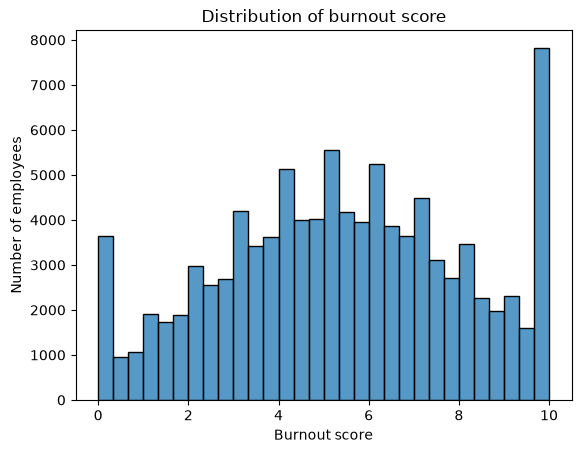

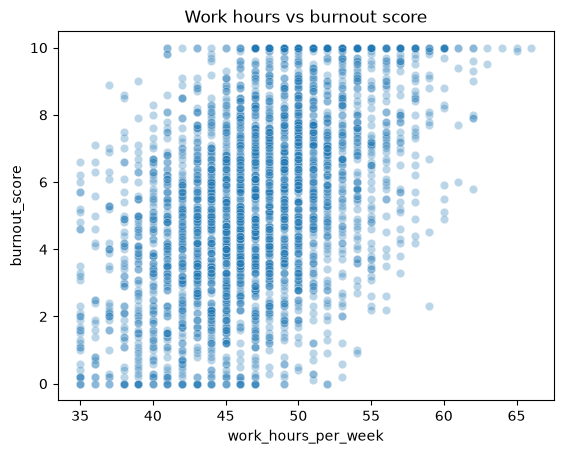

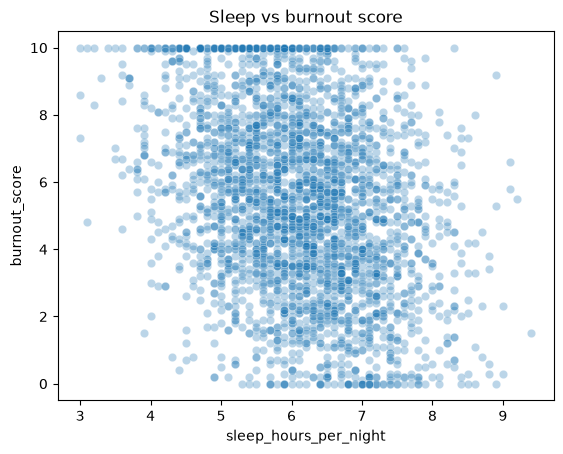

In [5]:
sns.histplot(df["burnout_score"], bins=30)
plt.title("Distribution of burnout score")
plt.xlabel("Burnout score"); plt.ylabel("Number of employees")
plt.show()

sample = df.sample(3000, random_state=42)
sns.scatterplot(data=sample, x="work_hours_per_week", y="burnout_score", alpha=0.3)
plt.title("Work hours vs burnout score")
plt.show()

sns.scatterplot(data=sample, x="sleep_hours_per_night", y="burnout_score", alpha=0.3)
plt.title("Sleep vs burnout score")
plt.show()

Burnout scores form a broad hill around 5.4, with spikes at exactly 0 and 10.<br>
Burnout goes up as work hours go up, and goes down as sleep goes up (3,000 random employees are shown so the dots don't pile up).

### Correlation between the main variables

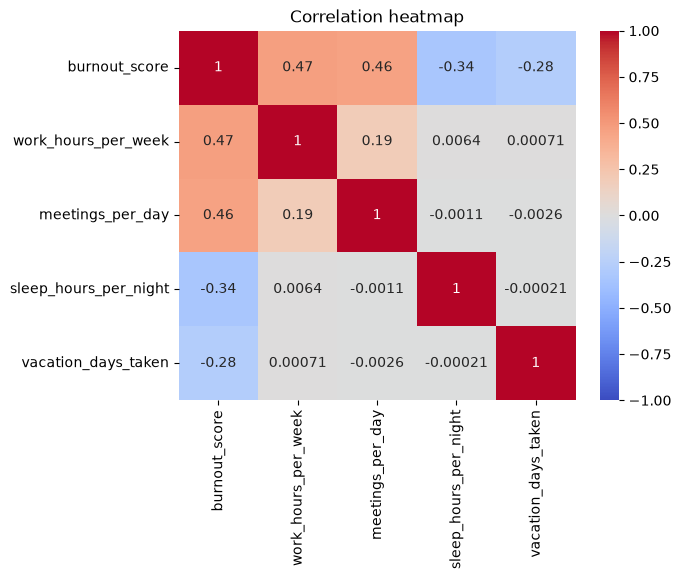

In [6]:
cols = ["burnout_score", "work_hours_per_week", "meetings_per_day", "sleep_hours_per_night", "vacation_days_taken"]
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.show()

Burnout has a positive correlation with work hours (0.47) and meetings (0.46), and a negative correlation with sleep (-0.34) and vacation days (-0.28). Correlation only shows that two things move together, not that one causes the other.

## 3. Preprocessing

We removed columns that would give the answer away, then turned the text columns into numbers.

In [7]:
y = df["burnout_score"]

# columns removed: the answer itself, things measured together with burnout, things that probably come after burnout, and gender
X = df.drop(columns=["employee_id", "burnout_score", "burnout_level", "stress_score", "phq9_score", "phq9_category",
                     "gad7_score", "gad7_category", "seeks_mental_health_support", "uses_therapy",
                     "job_change_intention", "gender"])
print("before:", X.shape)

# one-hot encoding: each text column becomes 0/1 columns
X = pd.get_dummies(X, drop_first=True, dtype=int)
print("after :", X.shape)

before: (100000, 24)
after : (100000, 58)


Two preprocessing steps.
1. We removed 12 columns that would let the model cheat or that are results of burnout (for example `stress_score` is almost the same thing as burnout).
2. We one-hot encoded the text columns, because the model only works with numbers. This takes the table from 24 to 58 columns.

### Train / test split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(80000, 58) (20000, 58)


80,000 employees are used to train the model and 20,000 are kept aside for testing. The split is random, and `random_state=42` makes it repeatable.

### Scaling

In [9]:
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns)
X_train[["salary_usd", "sleep_hours_per_night"]].describe().loc[["mean", "std"]].round(2)

,salary_usd,sleep_hours_per_night
mean,0.0,-0.0
std,1.0,1.0


Salary is around $83,000, while sleep is around 6, so the columns are on very different scales. Scaling puts every column at mean 0 and standard deviation 1. The scaler learns from the training data only, then is applied to the test data.

## 4. Building the model

We used linear regression as our model.

In [10]:
model = LinearRegression()
model.fit(X_train, y_train)
print("model trained")

model trained


Linear regression gives each column a weight and adds them up to predict the burnout score. To know whether the model is actually useful, we compared it with a baseline that ignores every column and always predicts the average burnout score.

## 5. Measuring performance

In [11]:
pred = model.predict(X_test)
baseline = np.full(len(y_test), y_train.mean())

print("baseline -> MAE:", round(mean_absolute_error(y_test, baseline), 2), " R2:", round(r2_score(y_test, baseline), 2))
print("model    -> MAE:", round(mean_absolute_error(y_test, pred), 2), " R2:", round(r2_score(y_test, pred), 2))

baseline -> MAE: 2.2  R2: -0.0
model    -> MAE: 1.15  R2: 0.71


**MAE** (mean absolute error) is the average size of the mistake in score points, so lower is better. **R2** is the share of the ups and downs in burnout the model explains (0 means no better than the average, 1 means perfect). Both are measured on the 20,000 test employees the model has not seen.

## 6. What we found

We checked how the model does on the training data compared with the test data, and which variables carry the most weight.

train -> MAE: 1.14  R2: 0.71
test  -> MAE: 1.15  R2: 0.71
work_hours_per_week        1.04
sleep_hours_per_night     -0.90
meetings_per_day           0.89
vacation_days_taken       -0.75
social_support_score      -0.60
exercise_days_per_week    -0.55
manager_support_score     -0.46
deadline_pressure_score    0.38
autonomy_score            -0.26
seniority_level_Lead       0.16
dtype: float64


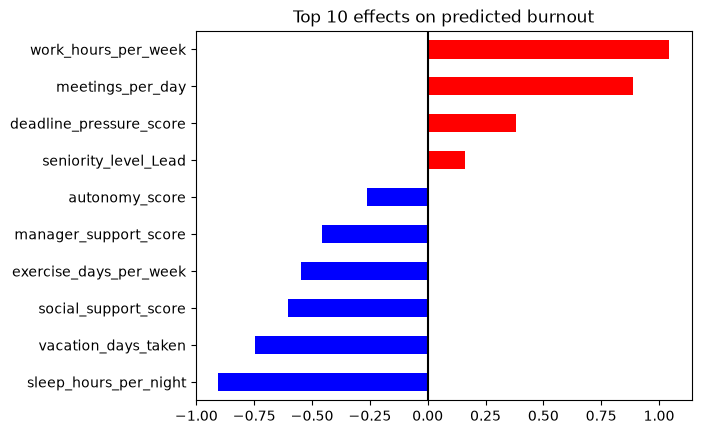

In [12]:
# does it work on the training data and the test data equally well?
print("train -> MAE:", round(mean_absolute_error(y_train, model.predict(X_train)), 2), " R2:", round(r2_score(y_train, model.predict(X_train)), 2))
print("test  -> MAE:", round(mean_absolute_error(y_test, pred), 2), " R2:", round(r2_score(y_test, pred), 2))

# which variables matter? (weights; + raises predicted burnout, - lowers it)
coef = pd.Series(model.coef_, index=X.columns)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
print(top.round(2))

top.sort_values().plot(kind="barh", color=["red" if v > 0 else "blue" for v in top.sort_values()])
plt.axvline(0, color="black")
plt.title("Top 10 effects on predicted burnout")
plt.show()

In [13]:
# Extract and display the most impactful variables
coefficients = pd.Series(model.coef_, index=X_train.columns)

print("Largest Positive Effects (Increases Burnout):")
print(coefficients.nlargest(5))

print("\nLargest Negative Effects (Decreases Burnout):")
print(coefficients.nsmallest(5))

Largest Positive Effects (Increases Burnout):
work_hours_per_week        1.044133
meetings_per_day           0.886072
deadline_pressure_score    0.382391
seniority_level_Lead       0.159673
seniority_level_Manager    0.135804
dtype: float64

Largest Negative Effects (Decreases Burnout):
sleep_hours_per_night    -0.904975
vacation_days_taken      -0.747209
social_support_score     -0.601892
exercise_days_per_week   -0.548037
manager_support_score    -0.456262
dtype: float64


**Can burnout be predicted?**<br>
Yes, quite well. Even after removing the symptom columns, the model explains **71% of the variation** in burnout scores (R² = 0.71). Its average error is **1.15 points** on the 0 to 10 scale, compared with 2.2 for the baseline, so it roughly halves the error.

**Which variables matter, and in which direction?**<br>
All columns were scaled, so each weight means: how many burnout points the prediction moves when that variable goes up by one standard deviation.

* **Raise burnout:** work hours (+1.04), meetings per day (+0.89), deadline pressure (+0.38) and being a Lead (+0.16).
* **Lower burnout:** sleep (−0.90), vacation days taken (−0.75), social support (−0.60), exercise days (−0.55), manager support (−0.46) and autonomy (−0.26).

Workload and recovery pull in opposite directions with almost the same strength. Support from people, at home and at work, also makes a clear difference.

**Does it work on new employees?**<br>
Yes. The scores on the training data (MAE 1.14, R² 0.71) and on the 20,000 unseen test employees (MAE 1.15, R² 0.71) are almost the same. So the model is not memorising the training data; it holds up on new people.

**Limits:** this is correlation, not cause. The data is a single snapshot and the scores are self-reported, so we can't say that cutting meetings *will* lower someone's burnout, only that the two move together. A next step would be to try a non-linear model (for example a random forest) and to check whether the effects differ by job role.